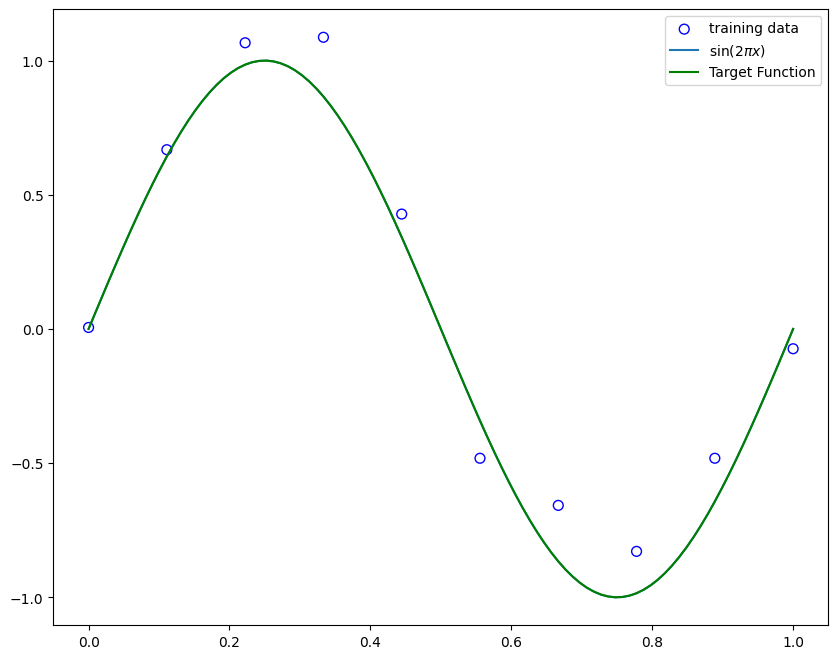

Iteration 1: Mean Cost 0.46928539872169495, Weight 0.07403412461280823, Bias 0.01668613776564598
Iteration 1000: Mean Cost 0.26820093393325806, Weight -1.3371168375015259, Bias 0.7389370799064636


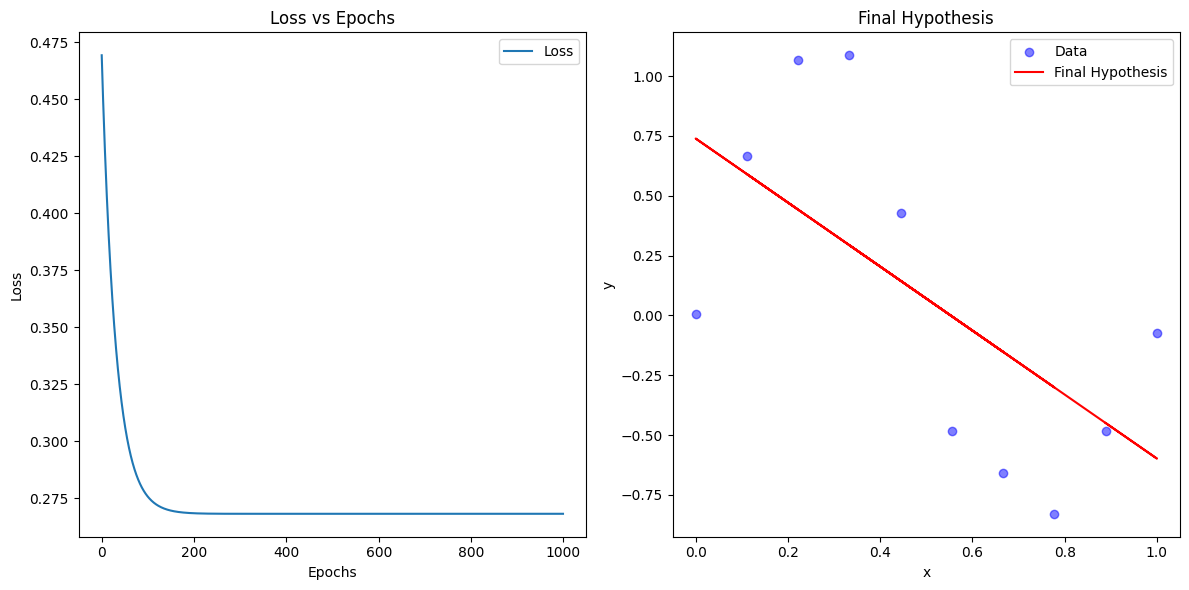

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc = nn.Sequential(
            nn.Linear(1, 10),
            nn.ReLU(),
            nn.Linear(10, 1)
        )

    def forward(self, x):
        return self.fc(x)

def create_toy_data(func, sample_size, std, domain=[0, 1]):
    x = np.linspace(domain[0], domain[1], sample_size)
    np.random.shuffle(x)
    y = func(x) + np.random.normal(scale=std, size=x.shape)
    return x, y

def sinusoidal(x):
    return np.sin(2 * np.pi * x)

x_train, y_train = create_toy_data(sinusoidal, 10, 0.20)
x_test = np.linspace(0, 1, 100)
y_test = sinusoidal(x_test)
x_train

y_train

x_test
y_test

plt.figure(figsize=[10,8])
plt.scatter(x_train, y_train, facecolor="none", edgecolor="b", s=50, label="training data")
plt.plot(x_test, y_test, label="$\sin(2\pi x)$")
plt.plot(x_test, y_test, "-g", label="Target Function")
plt.legend()
plt.show()

weights = torch.randn(1, requires_grad=True)
bias = torch.randn(1, requires_grad=True)
cost = []

def stochastic_gradient_descent_pytorch(x, y, iterations=1000, learning_rate=0.01, stopping_threshold=1e-6):
    x_tensor = torch.tensor(x, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    current_weight = torch.tensor(0.1, dtype=torch.float32, requires_grad=True)
    current_bias = torch.tensor(0.01, dtype=torch.float32, requires_grad=True)

    costs = []
    previous_cost = None

    for i in range(iterations):
        for j in range(len(x_tensor)):
            x_sample = x_tensor[j]
            y_sample = y_tensor[j]

            y_predicted = current_weight * x_sample + current_bias

            current_cost = (y_sample - y_predicted) ** 2 #MSE

            if previous_cost is not None and abs(previous_cost.item() - current_cost.item()) <= stopping_threshold:
                break

            previous_cost = current_cost

            current_weight.grad = None
            current_bias.grad = None

            current_cost.backward()

            with torch.no_grad():
                current_weight -= learning_rate * current_weight.grad
                current_bias -= learning_rate * current_bias.grad
                mean_cost = ((y_tensor - (current_weight * x_tensor + current_bias)) ** 2).mean()
        costs.append(mean_cost.item())
        if (i + 1) % 1000 == 0 or i == 0:
            print(f"Iteration {i + 1}: Mean Cost {mean_cost.item()}, Weight {current_weight.item()}, Bias {current_bias.item()}")

    return current_weight.item(), current_bias.item(), costs

weights, bias, cost = stochastic_gradient_descent_pytorch(x_train, y_train)

plt.figure(figsize=(12, 6))

# Loss vs Epochs
plt.subplot(1, 2, 1)
plt.plot(cost, label='Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss vs Epochs')
plt.legend()

# Final hypothesis
plt.subplot(1, 2, 2)
plt.scatter(x_train, y_train, label='Data', color='blue', alpha=0.5)
plt.plot(x_train, weights * x_train + bias, label='Final Hypothesis', color='red')
plt.xlabel('x')
plt.ylabel('y')
plt.title('Final Hypothesis')
plt.legend()

plt.tight_layout()
plt.show()

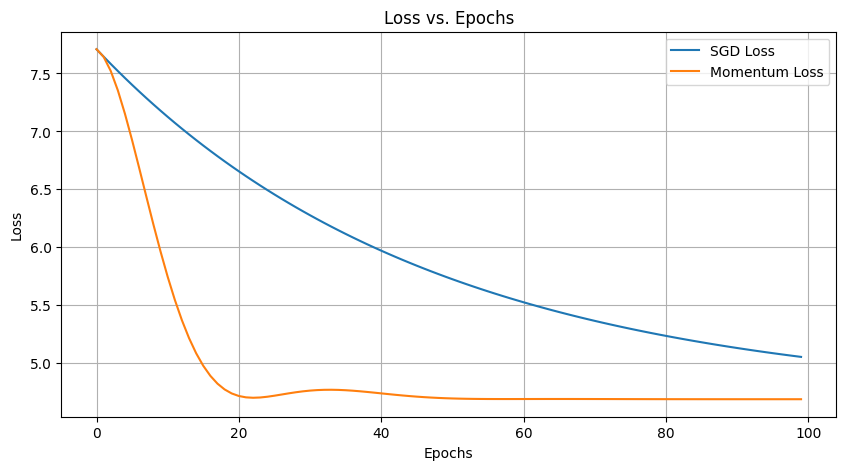

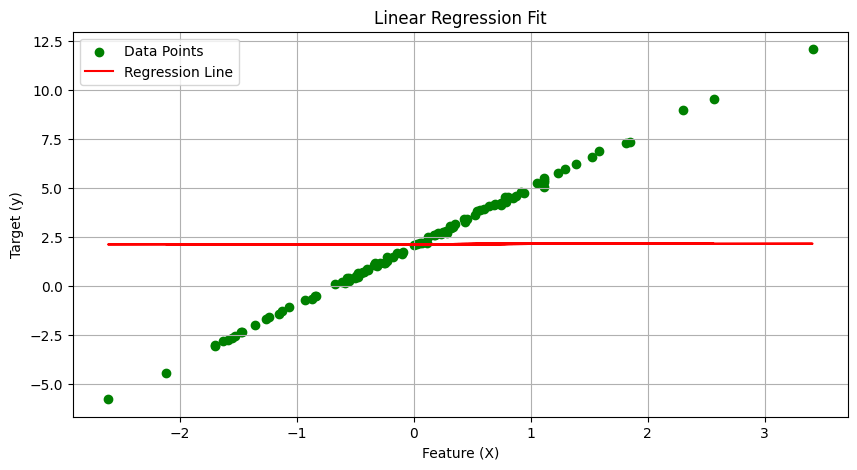

In [ ]:
import torch
import matplotlib.pyplot as plt

# Hyperparameters
learning_rate = 0.01
num_epochs = 100
reg_lambda = 0.1
momentum = 0.9


torch.manual_seed(0)


X_data = torch.randn(100, 1)
y_data = 3 * X_data + 2 + 0.1 * torch.randn(100, 1)

# Initialize weights and bias
weights = torch.randn(1, requires_grad=True)
bias = torch.randn(1, requires_grad=True)



loss_history_momentum = []


velocity_weights = torch.zeros_like(weights)
velocity_bias = torch.zeros_like(bias)


for epoch in range(num_epochs):

    predictions = X_data @ weights + bias
    mse_loss = torch.mean((predictions - y_data) ** 2) / 2
    reg_loss = reg_lambda * torch.sum(weights ** 2) / 2
    total_loss = mse_loss + reg_loss

    total_loss.backward()


    with torch.no_grad():
        velocity_weights = momentum * velocity_weights - learning_rate * (weights.grad + reg_lambda * weights)
        velocity_bias = momentum * velocity_bias - learning_rate * bias.grad
        weights += velocity_weights
        bias += velocity_bias
        weights.grad.zero_()
        bias.grad.zero_()

    loss_history_momentum.append(total_loss.item())


plt.figure(figsize=(10, 5))
plt.plot(loss_history_sgd, label='SGD Loss')
plt.plot(loss_history_momentum, label='Momentum Loss')
plt.title('Loss vs. Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()


with torch.no_grad():
    final_predictions = X_data @ weights + bias


plt.figure(figsize=(10, 5))
plt.scatter(X_data.numpy(), y_data.numpy(), color='green', label='Data Points')
plt.plot(X_data.numpy(), final_predictions.numpy(), color='red', label='Regression Line')
plt.title('Linear Regression Fit')
plt.xlabel('Feature (X)')
plt.ylabel('Target (y)')
plt.legend()
plt.grid()
plt.show()


ValueError: mount failed